# `cp` vs `cp_nr` -- what rounding the target costs, in mean performance

**The question.** `round()` is the ONLY step that fabricates zeros in the count models' target: `round(y·T/L) = 0` as soon as `L > 2yT`, so it is the **deep** spots that lose their small counts. `cp_nr` keeps the target continuous and is immune to it by construction. At identical model, seed, architecture, donors and genes, **the cp_nr - cp gap IS the cost of the rounding**, isolated.

**The two arms.** Two runs that differ ONLY by the common depth `T`:

| arm | run_id | TuPro | NSCLC | TLS |
|---|---|---|---|---|
| `median` | `pr_classic5_cp_vs_cp_nr_median` | 25 000 | 2 800 | 1 200 |
| `prod` | `pr_classic6_cp_vs_cp_nr` | 25 000 | 10 000 | 10 000 |

The three cohorts × two arms give a **dose-response**: the fraction of non-zero values destroyed by the rounding goes from 1.6% to 57.5%. If the gap stays zero even at 57.5%, the question is settled **by monotonicity for every larger `T`**, production depth included.

**Why paired by donor.** The donor effect dominates the spread (one same model goes from ~0.13 to ~0.22 depending on the donor on TuPro). Comparing two per-model intervals leaves that effect IN both, so they overlap even when one model wins on nearly every donor. The donor-by-donor difference cancels it exactly, and the CI on the difference is typically ~10x narrower. **Consequence for the wording: two overlapping intervals do NOT license saying "no difference".** Only a bound on the MAGNITUDE of the gap does, and that is what this table gives.

**Out of scope here:** calibration. `cp_nr` is excluded from it by decision (mean-performance control only). This notebook looks only at the correlation.

## 0. Config

In [7]:
import sys
import importlib
from pathlib import Path
import numpy as np
import pandas as pd

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))   # parent dir of src (notebooks are not pip-installed on the cluster)

import src.evaluation.benchmark_summary as bs
importlib.reload(bs)          # so editing benchmark_summary.py does not need a kernel restart
from src.evaluation.benchmark_summary import (
    discover_run_summaries, headline_registry, format_headline_registry, paired_donor_deltas,
)

# The two arms. count_common_depth is the ONLY difference between them (same 8 model types, same
# seed 42, same architecture, same preproc_id v5, same deferred chain, same corr selection).
RUNS = {
    "median": "pr_classic5_cp_vs_cp_nr_median",   # TuPro 25000 / NSCLC 2800 / TLS 1200
    "prod":   "pr_classic6_cp_vs_cp_nr",          # TuPro 25000 / NSCLC 10000 / TLS 10000
}
DATASETS = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS   = "r75"
METRICS  = ("pearson", "pearson_logmean")   # B = g*, then A = log1p(mu/depth_scale)

# The 4 matched pairs. LEFT = rounded target, RIGHT = continuous target; nothing else differs
# between the two members (same class, same loss, same head, same seed).
PAIRS = [
    ("poisson_cp",                          "poisson_cp_nr"),
    ("negativebinomial_hetero_noanchor_cp", "negativebinomial_hetero_noanchor_cp_nr"),
    ("negativebinomial_spotdisp_cp",        "negativebinomial_spotdisp_cp_nr"),
    ("negativebinomial_genedisp_cp",        "negativebinomial_genedisp_cp_nr"),
]
MODELS = [m for pair in PAIRS for m in pair]

# Fraction of NON-ZERO entries that round() sends to zero at each arm's T.
# These fractions are the x axis of the dose-response below.
ZERO_LOSS_PCT = {
    ("median", "10x_TuPro"): 1.6, ("median", "LUNG_CANCER"): 28.1, ("median", "TLS"): 57.5,
    ("prod",   "10x_TuPro"): 1.6, ("prod",   "LUNG_CANCER"):  2.5, ("prod",   "TLS"):  8.7,
}

# Both arms are loaded into ONE summaries list, with the arm prefixed onto the label. Two reasons:
# headline_registry restricts each (dataset, gene_set) block to the gene panel every summary
# SHARES, so loading them together makes the cross-arm comparison paired on genes too; and
# paired_donor_deltas can then pair any two labels, within OR across arms, from one frame.
summaries = []
for tag, run_id in RUNS.items():
    got = discover_run_summaries(PROJ / "results", run_id, DATASETS,
                                 radius=RADIUS, models=MODELS, lambda_keep=0.0)
    for s in got:
        s["label"] = f"{tag}::{s['label']}"
    summaries += got
    print(f"{tag:>6s}  {run_id:<32s}  {len(got):>2d} runs")

# A missing model means canal1 has not written its benchmark_summary.parquet yet -- the run is
# still going, or its canal1 job failed. Warn loudly: every table below would silently shrink.
found   = {s["label"] for s in summaries}
missing = [f"{t}::{m}" for t in RUNS for m in MODELS if f"{t}::{m}" not in found]
print(f"\n{len(summaries)} runs loaded out of {len(RUNS) * len(MODELS) * len(DATASETS)} expected")
if missing:
    print(f"(!) missing (canal1 not run yet?): {missing}")

median  pr_classic5_cp_vs_cp_nr_median    24 runs
  prod  pr_classic6_cp_vs_cp_nr           16 runs

40 runs loaded out of 48 expected


## 1. Headline, the two arms side by side

Full, shared gene panel, no top-n cutoff. Both estimators are shown: **`pearson`** = B = `g*` = the predictive mean of `log1p`, and **`pearson_logmean`** = A = `log1p(mu/depth_scale)`, which depends only on the fitted mean. A cp/cp_nr gap visible in A but not in B (or the reverse) is informative: A ignores the dispersion, B goes through the whole predictive.

In [8]:
stats, donor_points = headline_registry(summaries, metrics=METRICS)
print(format_headline_registry(stats, datasets=DATASETS, metrics=METRICS))

HEADLINE -- full shared gene panel. THREE DIFFERENT THINGS, do not swap them:
  SE / t-CI     spread of the MEAN over donors (patients resampled, gene panel fixed).
                One estimand, two presentations: t-CI = mean +/- t*·SE.  <- THE headline bar.
  PI-new-donor  where a NEW patient would land. Wider, and a different question entirely.
  gene-boot     genes resampled, donor cohort FIXED -> ZERO inter-donor variance.
                Gene-panel stability only; far narrower (N genes vs K donors).
LOPO folds share K-2 training donors (Bengio & Grandvalet 2004), so these intervals are
optimistic -- always read them next to the per-donor points (donor_points).

--- 10x_TuPro | pearson  (K=7 donors, N=3000 genes) ---
  median::poisson_cp_nr                      +0.1689  SE 0.0158  t-CI [+0.1304,+0.2075] (df 6, t* 2.45)  PI-new-donor [+0.0598,+0.2780]  gene-boot [+0.1639,+0.1738] (SE 0.0025)
  median::negativebinomial_hetero_noanchor_cp_nr +0.1679  SE 0.0123  t-CI [+0.1378,+0.1980] 

## 2. The paired gap `cp_nr` - `cp`

One row per (arm, dataset, pair, estimator). The `_cp` model is the **reference** and its `_nr` twin the comparand, so:

- **`delta_mean` > 0** → removing the rounding IMPROVES: the rounding was costing performance.
- **`delta_mean` ≈ 0 with a tight CI** → the rounding costs nothing, *and we can say so* (bound on the magnitude).
- **`excludes_zero`** → the 95% Student CI on the difference does not include 0.
- **`n_donors_better` / `n_donors_worse`** → at K = 6 to 8 donors, a constant sign is often more convincing than the CI itself.

Reminder: the LOPO CIs are optimistic (the folds share K-2 training donors, Bengio & Grandvalet 2004). To be read as a bound on the effect, not as a p-value.

In [9]:
rows = []
for tag in RUNS:
    for cp, nr in PAIRS:
        for m in METRICS:
            d = paired_donor_deltas(donor_points, reference=f"{tag}::{cp}",
                                    metric=m, datasets=DATASETS)
            if d.empty:
                continue
            d = d[d["model"] == f"{tag}::{nr}"].copy()   # keep ONLY the twin, not the other models
            d["arm"], d["pair"] = tag, cp
            rows.append(d)
gap = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

COLS = ["arm", "dataset", "pair", "metric", "reference_mean", "delta_mean", "delta_sem",
        "delta_ci_lo", "delta_ci_hi", "n_donors_better", "n_donors_worse", "excludes_zero"]
if gap.empty:
    print("(!) nothing to pair -- both members of at least one pair are missing.")
else:
    with pd.option_context("display.width", 220, "display.max_rows", 300):
        print(gap[COLS].sort_values(["metric", "dataset", "arm", "pair"]).to_string(index=False))

   arm     dataset                                pair          metric  reference_mean  delta_mean  delta_sem  delta_ci_lo  delta_ci_hi  n_donors_better  n_donors_worse  excludes_zero
median   10x_TuPro        negativebinomial_genedisp_cp         pearson        0.160272    0.004466   0.004323    -0.006112     0.015044                4               3          False
median   10x_TuPro negativebinomial_hetero_noanchor_cp         pearson        0.165344    0.002520   0.001211    -0.000442     0.005482                6               1          False
median   10x_TuPro        negativebinomial_spotdisp_cp         pearson        0.160541   -0.000108   0.002133    -0.005327     0.005112                4               3          False
median   10x_TuPro                          poisson_cp         pearson        0.165599    0.003336   0.001820    -0.001118     0.007789                5               2          False
median LUNG_CANCER        negativebinomial_genedisp_cp         pearson        0.

## 3. The dose-response

On the x axis: how much the rounding actually destroys at this `T`. On the y axis: what it costs. Each point is one (arm, dataset), so the six points span 1.6% to 57.5% destruction.

**How to read it.** A flat line at zero over the whole range = the rounding costs nothing even when it destroys the majority of the non-zero values, and the question is closed for every larger `T`. A positive slope = the cost is real and reads directly in the units of the destruction.

**Internal control:** TuPro appears twice at the same x (1.6%), since `T` = 25,000 in both arms. Those two points must coincide; their gap measures the retraining noise, not an effect.

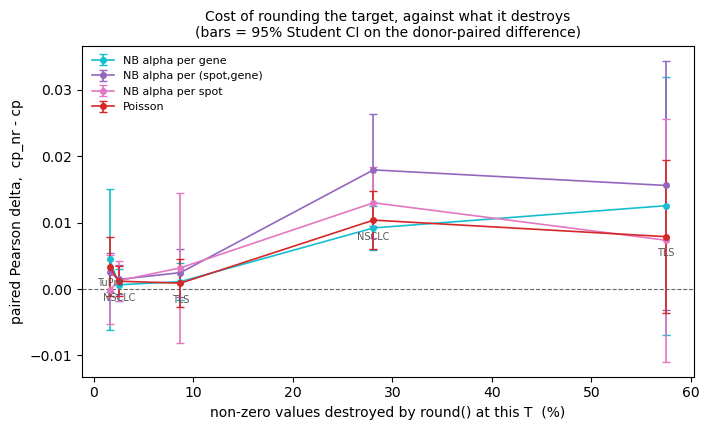

In [10]:
import matplotlib.pyplot as plt

# CANONICAL model -> color map.
# Keyed on model_type, never positional. The two restricted-dispersion NB heads take the UNUSED
# slots C6 pink and C9 cyan on purpose: green and blue already belong to spot_homoscedastic and
# homoscedastic, so reusing them would give one model two colors across every figure.
PAIR_COLOR = {
    "poisson_cp":                          "#d62728",   # red
    "negativebinomial_hetero_noanchor_cp": "#9467bd",   # purple
    "negativebinomial_spotdisp_cp":        "#e377c2",   # pink
    "negativebinomial_genedisp_cp":        "#17becf",   # cyan
}
PAIR_SHORT = {
    "poisson_cp":                          "Poisson",
    "negativebinomial_hetero_noanchor_cp": "NB alpha per (spot,gene)",
    "negativebinomial_spotdisp_cp":        "NB alpha per spot",
    "negativebinomial_genedisp_cp":        "NB alpha per gene",
}
DS_SHORT = {"10x_TuPro": "TuPro", "TLS": "TLS", "LUNG_CANCER": "NSCLC"}

g = gap[gap["metric"] == "pearson"].copy()
g["loss"] = [ZERO_LOSS_PCT[(a, d)] for a, d in zip(g["arm"], g["dataset"])]

fig, ax = plt.subplots(figsize=(7.2, 4.4))
for pair, sub in g.groupby("pair"):
    sub = sub.sort_values("loss")
    ax.errorbar(sub["loss"], sub["delta_mean"],
                yerr=[sub["delta_mean"] - sub["delta_ci_lo"],
                      sub["delta_ci_hi"] - sub["delta_mean"]],
                marker="o", ms=4, capsize=3, lw=1.2,
                color=PAIR_COLOR[pair], label=PAIR_SHORT[pair])
for _, r in g[g["pair"] == PAIRS[0][0]].iterrows():
    ax.annotate(DS_SHORT[r["dataset"]], (r["loss"], r["delta_mean"]),
                textcoords="offset points", xytext=(0, -14), ha="center", fontsize=7, color="0.35")

ax.axhline(0.0, color="0.4", lw=0.8, ls="--")
ax.set_xlabel("non-zero values destroyed by round() at this T  (%)")
ax.set_ylabel("paired Pearson delta,  cp_nr - cp")
ax.set_title("Cost of rounding the target, against what it destroys\n"
             "(bars = 95% Student CI on the donor-paired difference)", fontsize=10)
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

## 4. Verdict, in one table

The most unfavorable gap observed over the whole destruction range, per estimator. That is the number to cite: **a bound on the cost of the rounding**, not an absence of effect.

In [11]:
if not gap.empty:
    v = (gap.assign(absdelta=gap["delta_mean"].abs())
            .sort_values("absdelta", ascending=False)
            .groupby("metric")
            .head(3)[["metric", "arm", "dataset", "pair", "delta_mean",
                      "delta_ci_lo", "delta_ci_hi", "excludes_zero"]])
    print("The 3 largest-MAGNITUDE gaps per estimator:\n")
    print(v.to_string(index=False))

    worst = gap.reindex(gap["delta_mean"].abs().sort_values(ascending=False).index).iloc[0]
    print(f"\nWorst case across all conditions: {worst['delta_mean']:+.4f} Pearson "
          f"({worst['pair']}, {worst['dataset']}, arm {worst['arm']}, {worst['metric']}), "
          f"IC [{worst['delta_ci_lo']:+.4f}, {worst['delta_ci_hi']:+.4f}].")
    print(f"Number of conditions whose CI excludes zero: "
          f"{int(gap['excludes_zero'].sum())} / {len(gap)}.")

The 3 largest-MAGNITUDE gaps per estimator:

         metric    arm     dataset                                pair  delta_mean  delta_ci_lo  delta_ci_hi  excludes_zero
        pearson median LUNG_CANCER negativebinomial_hetero_noanchor_cp    0.017958     0.009563     0.026353           True
        pearson median         TLS negativebinomial_hetero_noanchor_cp    0.015610    -0.003203     0.034423          False
        pearson median LUNG_CANCER        negativebinomial_spotdisp_cp    0.013002     0.007682     0.018323           True
pearson_logmean median         TLS        negativebinomial_genedisp_cp    0.012490    -0.006712     0.031691          False
pearson_logmean median         TLS negativebinomial_hetero_noanchor_cp    0.011265    -0.003027     0.025557          False
pearson_logmean median LUNG_CANCER                          poisson_cp    0.010381     0.005979     0.014784           True

Worst case across all conditions: +0.0180 Pearson (negativebinomial_hetero_noanchor_cp

## 5. Report figure

The cell 9 figure is a diagnostic. This one is the version intended for the supplement, and it differs on three points.

**Categorical x axis.** Five conditions were measured, not a continuum. A continuous axis would suggest that we measured between the points. The five conditions are ordered by increasing destruction.

**The production regime is shaded.** The three leftmost conditions are the depths actually kept (TuPro 25,000, NSCLC 10,000, TLS 10,000). Note that TuPro exists only in the `median` arm, but its `T` there IS already its production value, so it counts in the production regime.

**Filled = significant.** Filled marker when the 95% CI excludes zero, hollow otherwise. That is what distinguishes "no effect" from "effect not detected" without having to read the numbers.

Vocabulary: no code identifier in the figure. `cp_nr` becomes "do not round the target", the heads become "Poisson" / "NB, free / per-spot / per-gene dispersion".

saved -> cp_vs_cp_nr_rounding_cost.pdf  (+ .png)


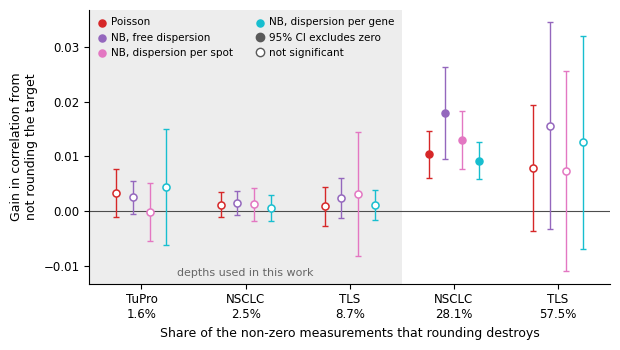

In [12]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

FIGDIR = PROJ / "results" / "_analysis" / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)
STEM = "cp_vs_cp_nr_rounding_cost"

# CANONICAL model -> color map, keyed on model_type;
# Do NOT re-pick these: the six original models
# keep their colors across every figure, and the two restricted-dispersion NB heads deliberately
# take the UNUSED slots (C6 pink, C9 cyan) rather than shifting anyone. Green and blue in
# particular are already spot_homoscedastic and homoscedastic, so reusing them here would make one
# model wear two colors across every figure.
SERIES = [
    ("poisson_cp",                          "Poisson",                  "#d62728"),   # red
    ("negativebinomial_hetero_noanchor_cp", "NB, free dispersion",      "#9467bd"),   # purple
    ("negativebinomial_spotdisp_cp",        "NB, dispersion per spot",  "#e377c2"),   # pink
    ("negativebinomial_genedisp_cp",        "NB, dispersion per gene",  "#17becf"),   # cyan
]
DS_SHORT = {"10x_TuPro": "TuPro", "TLS": "TLS", "LUNG_CANCER": "NSCLC"}

# The depths actually used in this work: TuPro 25000 / NSCLC 10000 / TLS 10000. Listed explicitly
# rather than inferred from the arm name, because TuPro appears only in the "median" arm and its T
# THERE is already 25000, i.e. its production value -- inferring from the arm would misclassify it.
PROD_CONDS = {("median", "10x_TuPro"), ("prod", "LUNG_CANCER"), ("prod", "TLS")}

g = gap[gap["metric"] == "pearson"].copy()
g["loss"] = [ZERO_LOSS_PCT[(a, d)] for a, d in zip(g["arm"], g["dataset"])]

# One x slot per MEASURED condition, ordered by destruction. Categorical because five conditions
# are not a continuum: a continuous axis would imply interpolation that was never run, and it
# would crush the three production conditions into the first tenth of the axis.
conds = g[["arm", "dataset", "loss"]].drop_duplicates().sort_values("loss").reset_index(drop=True)
xpos   = {(r["arm"], r["dataset"]): i for i, r in conds.iterrows()}
labels = [f"{DS_SHORT[r['dataset']]}\n{r['loss']:.1f}%" for _, r in conds.iterrows()]
k_prod = max(xpos[c] for c in PROD_CONDS if c in xpos)   # last slot of the operating regime

fig, ax = plt.subplots(figsize=(6.3, 3.6))
ax.axvspan(-0.5, k_prod + 0.5, color="0.93", lw=0, zorder=0)
ax.axhline(0.0, color="0.3", lw=0.8, zorder=1)

off = np.linspace(-0.24, 0.24, len(SERIES))
for j, (pair, name, color) in enumerate(SERIES):
    s = g[g["pair"] == pair].copy()
    if s.empty:
        continue
    s["x"] = [xpos[(a, d)] + off[j] for a, d in zip(s["arm"], s["dataset"])]
    s = s.sort_values("x")
    ax.errorbar(s["x"], s["delta_mean"],
                yerr=[s["delta_mean"] - s["delta_ci_lo"], s["delta_ci_hi"] - s["delta_mean"]],
                fmt="none", ecolor=color, elinewidth=1.0, capsize=2.5, zorder=2)
    sig = s["excludes_zero"].to_numpy(dtype=bool)
    # The significant scatter carries the legend label and is called even when empty, so a series
    # with no significant point still appears in the legend with its color.
    ax.scatter(s["x"][sig], s["delta_mean"][sig], s=26, color=color, zorder=3, label=name)
    ax.scatter(s["x"][~sig], s["delta_mean"][~sig], s=26, facecolors="white",
               edgecolors=color, linewidths=1.1, zorder=3)

ax.set_xticks(range(len(conds)))
ax.set_xticklabels(labels, fontsize=8.5)
ax.set_xlim(-0.5, len(conds) - 0.5)
ax.set_xlabel("Share of the non-zero measurements that rounding destroys", fontsize=9)
ax.set_ylabel("Gain in correlation from\nnot rounding the target", fontsize=9)
ax.tick_params(axis="y", labelsize=8.5)


# ax.text(k_prod + 0.42, ax.get_ylim()[1], "depths used in this work  ",
#         ha="right", va="top", fontsize=8, color="0.35")
# x in data coords, y in axes fraction -- immune to later ylim changes, and out of the
# legend's way at the top. Centerd on the band so it reads as the band's caption.
ax.text(k_prod / 2, 0.02, "depths used in this work",
        transform=ax.get_xaxis_transform(),
        ha="center", va="bottom", fontsize=8, color="0.4")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

handles, names = ax.get_legend_handles_labels()
handles += [Line2D([], [], marker="o", ls="", color="0.35", label="95% CI excludes zero"),
            Line2D([], [], marker="o", ls="", mfc="white", mec="0.35", label="not significant")]
# ax.legend(handles=handles, fontsize=7.5, frameon=False, ncol=2, loc="upper left")
band_frac = (k_prod + 1) / len(conds)          # right edge of the shaded zone, in axes fraction
leg = ax.legend(handles=handles, fontsize=7.5, frameon=False, ncol=2,
                loc="upper left",
                bbox_to_anchor=(0.0, 0.0, band_frac, 1.0), mode="expand",
                borderaxespad=0.3, handlelength=1.0,
                handletextpad=0.4, columnspacing=0.8)

fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIGDIR / f"{STEM}.{ext}", dpi=300, bbox_inches="tight")
print(f"saved -> {(FIGDIR / (STEM + '.pdf')).name}  (+ .png)")
plt.show()